# AML Baseline Training on IBM's Synthetic Dataset

Baseline notebook to detect money laundering using transaction-level and simple entity features

What this does:
- Loads mini CSV, cleans types, derives basic features
- Time-based split (avoid leakage)
- Entity aggregates from train only, merged into test
- Model: LightGBM for now, try random forrest
- Evaluation: PR-AUC, precision/recall at alert budget; top-k alerts table



In [1]:
# All the imports ()
import importlib, subprocess, sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score, precision_recall_curve, classification_report
from sklearn.ensemble import RandomForestClassifier

import lightgbm as lgb



### Data Loading

In [2]:
# Configuration
DATA_PATH = '../Datasets/trans_3000p2_list.csv' # 45 million row (use less?)
TARGET_COL = 'Is Laundering'
RANDOM_STATE = 42
ALERT_RATE = 0.001 # 0.1% of scored transactions flagged

print('Data path:', DATA_PATH)


Data path: ../Datasets/trans_3000p2_list.csv


In [3]:
#~1:45

# Load and basic cleaning
df = pd.read_csv(DATA_PATH)
# Strip whitespace from column names and string values
df.columns = df.columns.str.strip()
for c in df.columns:
    if df[c].dtype == 'object':
        df[c] = df[c].astype(str).str.strip()

# Set timestamp to usable date and amounts to numerics (more efficient)
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
for amt_col in ['Amount Received', 'Amount Paid']:
    df[amt_col] = pd.to_numeric(df[amt_col], errors='coerce')

# Drop rows with missing essentials (should be none)
df = df.dropna(subset=['Timestamp', 'Amount Received', 'Amount Paid', TARGET_COL]).copy()
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors='coerce').fillna(0).astype(int)

# Removed sorting due to huggggeee performance issue

print(df.head(3))
print('Rows:', len(df), '| positives:', int((df[TARGET_COL]==1).sum()))


KeyboardInterrupt: 

### Feature Engineering @ Transaction Level

In [ ]:
#~12.5

###########################################
# Feature engineering (transaction level)
# Added:
#   Spread between paid and receieved
#   Is it a change in currency
#   Is it from the same bank 
#   Is it a transfer to own account
#   hour, day of week, weekend or not
###########################################
def build_tx_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out['fx_spread'] = out['Amount Paid'] - out['Amount Received']
    out['is_cross_cur'] = (out['Receiving Currency'] != out['Payment Currency']).astype(int)
    out['same_bank'] = (out['From Bank'] == out['To Bank']).astype(int)
    out['self_transfer'] = (out['Account'] == out['To Account']).astype(int)
    out['hour'] = out['Timestamp'].dt.hour
    out['dow'] = out['Timestamp'].dt.dayofweek
    out['is_weekend'] = out['dow'].isin([5, 6]).astype(int)
    return out

df = build_tx_features(df)
df.head(10)


In [ ]:
#~30

# Time based split: train = first 80%, test = last 20% by Timestamp (does NOT require the sorting I commented out btw, by quantile)
required_feats = ['fx_spread','is_cross_ccy','same_bank','self_transfer','hour','dow','is_weekend']
if any(f not in df.columns for f in required_feats):
    try:
        df = build_tx_features(df)
    except Exception as _e:
        pass
split_time = df['Timestamp'].quantile(0.80) # <- split here
train_df = df[df['Timestamp'] <= split_time].copy()
test_df  = df[df['Timestamp'] >  split_time].copy()

print('Train rows:', len(train_df), '| Test rows:', len(test_df))
print('Positives (train/test):', int(train_df[TARGET_COL].sum()), int(test_df[TARGET_COL].sum()))


In [ ]:
# ~2:30

# For reffence on agg: https://www.w3schools.com/python/pandas/ref_df_agg.asp
# Entity aggregates computed on TRAIN only, then merged into both
def entity_aggs(train: pd.DataFrame, key: str, prefix: str) -> pd.DataFrame:
    tmp = train.copy()
    agg_dict = {
        f'{prefix}_tx_count': ('Timestamp', 'size'),
        f'{prefix}_amt_paid_mean': ('Amount Paid', 'mean'),
        f'{prefix}_amt_recv_mean': ('Amount Received', 'mean'),
        f'{prefix}_cross_ccy_rate': ('is_cross_cur', 'mean'),
    }
    g = tmp.groupby(key).agg(**agg_dict).reset_index()
    return g

acc_aggs   = entity_aggs(train_df, 'Account', 'acc')
toacc_aggs = entity_aggs(train_df, 'To Account', 'toacc')
fb_aggs    = entity_aggs(train_df, 'From Bank', 'fb')
tb_aggs    = entity_aggs(train_df, 'To Bank', 'tb')

def merge_aggs(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame
    out = out.merge(acc_aggs,   on='Account',    how='left')
    out = out.merge(toacc_aggs, on='To Account', how='left')
    out = out.merge(fb_aggs,    on='From Bank',  how='left')
    out = out.merge(tb_aggs,    on='To Bank',    how='left')
    return out

train_df = merge_aggs(train_df)
test_df  = merge_aggs(test_df)

# Fill unseen entities in test with zeros
agg_cols = [c for c in train_df.columns if c.startswith(('acc_', 'toacc_', 'fb_', 'tb_'))]
train_df[agg_cols] = train_df[agg_cols].fillna(0.0)
test_df[agg_cols]  = test_df[agg_cols].fillna(0.0)

len(agg_cols), agg_cols[:6]


In [ ]:
# Feature sets (column info)
numeric_features = [
    'Amount Received', 'Amount Paid', 'fx_spread',
    'is_cross_cur', 'same_bank', 'self_transfer',
    'hour', 'dow', 'is_weekend'
] + [c for c in train_df.columns if c.startswith(('acc_', 'toacc_', 'fb_', 'tb_'))]

categorical_features = ['Payment Format', 'Receiving Currency', 'Payment Currency']

drop_features = ['Timestamp', 'From Bank', 'Account', 'To Bank', 'To Account']

feature_cols = numeric_features + categorical_features

print('Numeric features:', len(numeric_features))
print('Categorical features:', len(categorical_features))
print('Sample features:', feature_cols[:8])


#### OPTIONAL: Offload the engineered training set to local machine

In [ ]:
# Save first 100 for visibility (recommeneded)
test_df.head(100).to_csv('../datasets/engineered_testing_mini.csv')

In [ ]:
# Save entire test and train (NOT recommended ~10GB)

test_df.to_csv("../datasets/engineered_testing.csv")
train_df.to_csv("../datasets/engineered_training.csv")

#### Quick Load (if saved)

In [3]:
import os
import sys

if (not os.path.isfile("../datasets/engineered_testing.csv") 
    or not os.path.isfile("../datasets/engineered_training.csv")): 
        print("Datasets not found") 
        sys.exit()

test_df = pd.read_csv("../datasets/engineered_testing.csv")
train_df = pd.read_csv("../datasets/engineered_training.csv")
test_df = test_df.head(4_000_000)
train_df = train_df.head(1_000_000)
agg_cols = [c for c in train_df.columns if c.startswith(("acc_", "toacc_", "fb_", "tb_"))]


# Feature sets (column info) — same as LightGBM baseline
numeric_features = [
    "Amount Received",
    "Amount Paid",
    "fx_spread",
    "is_cross_cur",
    "same_bank",
    "self_transfer",
    "hour",
    "dow",
    "is_weekend",
] + agg_cols

categorical_features = ["Payment Format", "Receiving Currency", "Payment Currency"]

feature_cols = numeric_features + categorical_features

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Sample features:", feature_cols[:8])


Numeric features: 25
Categorical features: 3
Sample features: ['Amount Received', 'Amount Paid', 'fx_spread', 'is_cross_cur', 'same_bank', 'self_transfer', 'hour', 'dow']


### Training (PMML for SnapML/Triton)
Uses a PMML-friendly sklearn LogisticRegression (dense OneHotEncoder) so the exported PMML stays within SnapML-supported ops; no local SnapML dependency required.

In [4]:
# SnapML-compatible PMML pipeline (Tree ensemble on numeric features)
from sklearn.compose import ColumnTransformer
from sklearn2pmml.pipeline import PMMLPipeline
from sklearn import set_config
from sklearn.ensemble import GradientBoostingClassifier
import json

# SnapML PMML backend does not accept string DataField inputs, so encode categorical columns to integer codes
cat_maps = {}
for col in categorical_features:
    cats = sorted(train_df[col].dropna().unique())
    cat_maps[col] = {v: i for i, v in enumerate(cats)}
    train_df[col + "_enc"] = train_df[col].map(cat_maps[col]).fillna(-1).astype(int)
    test_df[col + "_enc"] = test_df[col].map(cat_maps[col]).fillna(-1).astype(int)

encoded_categorical_features = [f"{c}_enc" for c in categorical_features]
feature_cols = numeric_features + encoded_categorical_features

# SnapML supports simple passthrough columns; avoid OneHotEncoder to keep PMML minimal
set_config(transform_output='pandas')
preprocess = ColumnTransformer(
    transformers=[('all', 'passthrough', feature_cols)],
    remainder='drop'
)

# Tree ensemble yields TreeModel/MiningModel in PMML, which ibmsnapml expects
classifier = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_STATE
)
classifier_name = 'sklearn GradientBoostingClassifier (PMML tree ensemble)'

pmml_pipeline = PMMLPipeline(
    steps=[
        ('preprocess', preprocess),
        ('classifier', classifier),
    ]
)

X_train = train_df[feature_cols].copy()
y_train = train_df[TARGET_COL].astype(int).copy()
X_test  = test_df[feature_cols].copy()
y_test  = test_df[TARGET_COL].astype(int).copy()

pmml_pipeline.fit(X_train, y_train)
print(f'Training complete with {classifier_name}')

# Persist category mappings for inference pipelines that must feed numeric codes (SnapML disallows string inputs)
map_path = "../Models/category_mappings.json"
with open(map_path, "w") as f:
    json.dump(cat_maps, f, indent=2)
print("Saved category code maps to", map_path)


Training complete with sklearn GradientBoostingClassifier (PMML tree ensemble)
Saved category code maps to ../Models/category_mappings.json


### Evaluation

Average Precision (PR-AUC): 0.0015


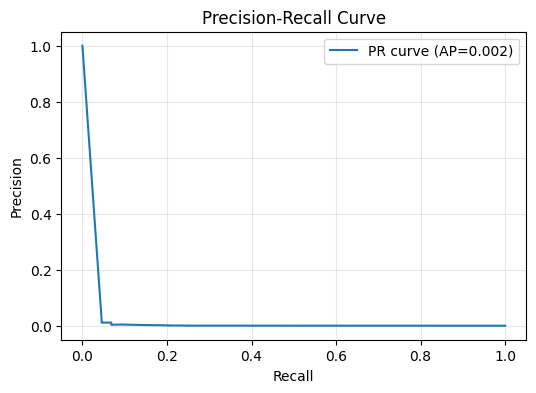

Positives in test: 44 out of 4000000


In [5]:
# PR-AUC and PR curve (SnapML-compatible)
if hasattr(pmml_pipeline[-1], 'predict_proba'):
    y_score = pmml_pipeline.predict_proba(X_test)[:, 1]
else:
    y_score = pmml_pipeline.decision_function(X_test)

ap = average_precision_score(y_test, y_score)
print(f'Average Precision (PR-AUC): {ap:.4f}')

prec, rec, thr = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(6,4))
plt.plot(rec, prec, label=f'PR curve (AP={ap:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print('Positives in test:', int(y_test.sum()), 'out of', len(y_test))


In [ ]:
# Evaluate at alert budget (top-k by score)
def eval_at_alert_rate(y_true: pd.Series, scores: np.ndarray, rate: float = 0.001):
    n = len(scores)
    k = max(1, int(n * rate))
    order = np.argsort(scores)[::-1]
    top_idx = order[:k]
    tp = int(y_true.iloc[top_idx].sum())
    precision = tp / k
    recall = tp / int(y_true.sum()) if int(y_true.sum()) > 0 else np.nan
    return k, precision, recall

k, p_at_k, r_at_k = eval_at_alert_rate(y_test, y_score, rate=ALERT_RATE)
print(f'Alert rate: {ALERT_RATE*100:.3f}% -> top-{k} rows')
print(f'Precision@k: {p_at_k:.4f} | Recall@k: {r_at_k:.4f}')


In [6]:
# Feature importance / coefficients
pre = pmml_pipeline.named_steps['preprocess']
clf = pmml_pipeline.named_steps['classifier']
try:
    fe_names = pre.get_feature_names_out()
except Exception:
    transformed = pre.transform(X_test)
    fe_names = [f'f{i}' for i in range(transformed.shape[1])]

if hasattr(clf, 'coef_'):
    importances = np.abs(clf.coef_[0])
elif hasattr(clf, 'feature_importances_'):
    importances = clf.feature_importances_
else:
    importances = None

if importances is not None:
    imp = (pd.DataFrame({'feature': fe_names, 'importance': importances})
              .sort_values('importance', ascending=False)
              .head(20))
    display(imp)
else:
    print('Estimator does not expose coefficients/feature_importances_')


,feature,importance
9,all__acc_tx_count,5.853957e-01
17,all__fb_tx_count,3.735657e-01
21,all__tb_tx_count,2.545843e-02
0,all__Amount Received,1.133929e-02
1,all__Amount Paid,1.769219e-03
13,all__toacc_tx_count,1.674059e-03
12,all__acc_cross_ccy_rate,2.252479e-04
22,all__tb_amt_paid_mean,1.367643e-04
11,all__acc_amt_recv_mean,1.300353e-04
6,all__hour,1.230106e-04


### Conversion to PMML (SnapML / Triton)
Exports the fitted pipeline to a PMML file with only supported operations (dense OneHotEncoder + Logistic Regression).

In [7]:
import os
import datetime
from sklearn2pmml import sklearn2pmml

pmml_ts = datetime.datetime.now().strftime("%Y-%m-%d-%H-%M-%S")
pmml_path = f"../Models/pipeline_snapml_{pmml_ts}.pmml"
os.makedirs(os.path.dirname(pmml_path), exist_ok=True)

# Export to PMML; keep repr for easier inspection/debugging
sklearn2pmml(pmml_pipeline, pmml_path, with_repr=True)
print('PMML model saved to:', pmml_path)

# SnapML backend expects supported algorithmName; normalize after export
with open(pmml_path, 'r') as f:
    pmml_text = f.read()
# set to the minimal string SnapML accepts for boosted trees
pmml_text = pmml_text.replace('algorithmName="sklearn.ensemble._gb.GradientBoostingClassifier"',
                              'algorithmName="BoostingMachine"')
# also handle already-rewritten files
pmml_text = pmml_text.replace('algorithmName="BoostingMachineClassifier"',
                              'algorithmName="BoostingMachine"')
with open(pmml_path, 'w') as f:
    f.write(pmml_text)
print('Rewrote algorithmName to BoostingMachine for SnapML')


PMML model saved to: ../Models/pipeline_snapml_2025-12-01-17-34-48.pmml
Rewrote algorithmName to BoostingMachine for SnapML


In [8]:
import joblib

# after you build/fit your pipeline (e.g., pmml_pipeline)
joblib.dump(pmml_pipeline, "model.joblib")
print("wrote model.joblib")

wrote model.joblib
